# Dynamic Parallel Execution with  Map-Reduce using Send in LangGraph


Map-reduce operations are essential for efficient task decomposition and parallel processing.

It has two phases:

(1) `Map` - Break a task into smaller sub-tasks, processing each sub-task in parallel.

(2) `Reduce` - Aggregate the results across all of the completed, parallelized sub-tasks.


Setup Environment Variables

In [2]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

Define Agent State Schema

In [3]:
from typing_extensions import TypedDict
from pydantic import BaseModel
import operator
from typing import Annotated

# Define state
class Questions(BaseModel):
    questions: list[str]

class Answer(BaseModel):
    question: str
    answer: str

class Report(BaseModel):
    report: str

class OverallState(TypedDict):
    topic: str
    questions: list
    answers: Annotated[list, operator.add]
    report: str

## Define Agent Node Functions

Role of the Send Function:
- Dynamic Task Distribution: Utilizes the Send function to dispatch different states to multiple instances of a node, facilitating parallel execution.
- Flexible Workflow Management: Very useful when you do not have a fixed number of static edges to parallelize like in router agent. A simple example would be generating a random number of questions or steps to solve a problem and parallelizing the generation process for each of those questions or steps.

In [4]:
from langgraph.constants import Send
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o", temperature=0)

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_84807/3126946667.py:1: LangGraphDeprecatedSinceV10: Importing Send from langgraph.constants is deprecated. Please use 'from langgraph.types import Send' instead. Deprecated in LangGraph V1.0 to be removed in V2.0.
  from langgraph.constants import Send


In [5]:
# Node to generate questions
def generate_questions(state: OverallState):
    # sometimes gpt-4o just generates 5 questions always so feel free to play around with the following prompt
    # or you can also use gpt-4o-mini or other LLMs or just randomly select a subselt of questions from the response
    # just to demonstrate and see how Send works with a variable number of questions
    questions_prompt = """Generate a list of concise sub-questions related to this overall topic: {topic}
                          which would help build a good report.
                          Follow these rules for question generation:
                            - Do not create very long questions.
                            - Number of questions should always be 3 for simple topics (Birds, Animals, AI)
                              and 5 for more complex topics (Outlook for ..., Impact of ...)
                       """
    prompt = questions_prompt.format(topic=state["topic"])
    response = llm.with_structured_output(Questions).invoke(prompt)
    return {"questions": response.questions}

In [6]:
# Node to generate answer to one question
def generate_answer(state: Answer):
    answer_prompt = """Generate the answer about {question}."""
    prompt = answer_prompt.format(question=state["question"])
    response = llm.with_structured_output(Answer).invoke(prompt)
    return {"answers": [{"question": state["question"], "answer": response.answer}]}

In [7]:
# Node to continue to answers
def continue_to_answers(state: OverallState):
    return [Send("generate_answer", {"question": q}) for q in state["questions"]] # does the parallel execution

In [8]:
# Node to compile the report
def compile_report(state: OverallState):
    q_and_a = "\n\n".join(
        [f"Q: {qa['question']}\nA: {qa['answer']}" for qa in state["answers"]]
    )
    report_prompt = """Below are a bunch of questions and answers about topic:
                       {topic}.
                       Generate a detailed report from this about the topic.
                       {q_and_a}"""
    prompt = report_prompt.format(topic=state["topic"], q_and_a=q_and_a)
    response = llm.with_structured_output(Report).invoke(prompt)
    return {"report": response.report}

Create Agent

In [9]:
from langgraph.graph import StateGraph, START, END

# Compile the graph
graph = StateGraph(OverallState)
graph.add_node("generate_questions", generate_questions)
graph.add_node("generate_answer", generate_answer)
graph.add_node("compile_report", compile_report)

graph.add_edge(START, "generate_questions")
graph.add_conditional_edges("generate_questions",
                            continue_to_answers,
                            ["generate_answer"])
graph.add_edge("generate_answer", "compile_report")
graph.add_edge("compile_report", END)

# Compile the app
agent = graph.compile()

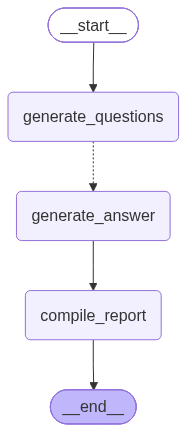

In [10]:
# Display the graph
from IPython.display import display, Image
Image(agent.get_graph().draw_mermaid_png())

In [12]:
from IPython.display import display, Markdown

for state in agent.stream({"topic": "Artificial Intelligence"}):
    print(state)
    if 'compile_report' in state:
        display(Markdown(state['compile_report']['report']))

{'generate_questions': {'questions': ['What are the primary types of artificial intelligence?', 'How does machine learning differ from traditional AI?', 'What are the ethical considerations surrounding AI development?', 'How is AI transforming various industries?', 'What are the future trends and challenges in AI technology?']}}
{'generate_answer': {'answers': [{'question': 'How is AI transforming various industries?', 'answer': "Artificial Intelligence (AI) is revolutionizing numerous industries by enhancing efficiency, improving decision-making, and creating new opportunities for innovation. Here's a look at how AI is transforming various sectors:\n\n### 1. **Healthcare**\n- **Diagnostics and Imaging:** AI algorithms analyze medical images with high accuracy, aiding in early detection of diseases like cancer.\n- **Personalized Medicine:** AI helps tailor treatments based on individual genetic profiles and health data.\n- **Robotics and Surgery:** AI-powered robots assist in surgeries

### Artificial Intelligence: A Comprehensive Overview

Artificial Intelligence (AI) is a rapidly evolving field that aims to create machines capable of performing tasks that typically require human intelligence. This report delves into the primary types of AI, the differences between machine learning and traditional AI, ethical considerations, industry transformations, and future trends and challenges.

---

### Types of Artificial Intelligence

AI can be categorized based on capabilities and functionalities:

1. **Reactive Machines**: Basic AI systems that perceive and act without memory or past experience. Example: IBM's Deep Blue.

2. **Limited Memory**: AI systems that use past experiences to inform decisions. Example: Self-driving cars.

3. **Theory of Mind**: Theoretical AI that understands human emotions and thoughts.

4. **Self-Aware AI**: Hypothetical AI with consciousness and self-awareness.

5. **Artificial Narrow Intelligence (ANI)**: AI designed for specific tasks, like virtual assistants.

6. **Artificial General Intelligence (AGI)**: Hypothetical AI with human-like problem-solving abilities.

7. **Artificial Superintelligence (ASI)**: Theoretical AI surpassing human intelligence in all aspects.

---

### Machine Learning vs. Traditional AI

**Approach and Methodology**:
- **Traditional AI**: Rule-based, symbolic reasoning, deterministic outcomes.
- **Machine Learning**: Data-driven, statistical methods, probabilistic outcomes.

**Learning and Adaptation**:
- **Traditional AI**: Static, limited adaptability.
- **Machine Learning**: Dynamic, self-improving.

**Applications**:
- **Traditional AI**: Expert systems, game playing.
- **Machine Learning**: Image recognition, predictive analytics.

**Complexity and Scalability**:
- **Traditional AI**: Complex rule management, scalability issues.
- **Machine Learning**: Handles large datasets, scalable solutions.

---

### Ethical Considerations in AI Development

1. **Bias and Fairness**: Mitigating biases to prevent discrimination.
2. **Transparency and Explainability**: Ensuring AI decisions are understandable.
3. **Privacy and Data Protection**: Safeguarding personal information.
4. **Accountability and Responsibility**: Clarifying who is accountable for AI actions.
5. **Autonomy and Control**: Maintaining human control over AI decisions.
6. **Security and Safety**: Designing secure and safe AI systems.
7. **Impact on Employment**: Addressing job displacement concerns.
8. **Moral and Ethical Decision-Making**: Aligning AI with human values.
9. **Global Inequality**: Promoting equitable access to AI benefits.
10. **Environmental Impact**: Minimizing AI's carbon footprint.

---

### AI Transformations Across Industries

1. **Healthcare**: AI enhances diagnostics, personalized medicine, and administrative efficiency.
2. **Finance**: AI improves fraud detection, trading, and customer service.
3. **Retail**: AI personalizes shopping experiences and optimizes inventory.
4. **Manufacturing**: AI predicts maintenance needs and streamlines production.
5. **Transportation**: AI powers autonomous vehicles and optimizes logistics.
6. **Education**: AI personalizes learning and automates administrative tasks.
7. **Agriculture**: AI optimizes farming practices and predicts yields.

---

### Future Trends and Challenges in AI

**Trends**:
1. **Explainable AI (XAI)**: Enhancing transparency in AI systems.
2. **AI in Healthcare**: Advancing personalized medicine and diagnostics.
3. **AI and Edge Computing**: Enabling real-time data processing.
4. **AI for Sustainability**: Addressing environmental challenges.
5. **Natural Language Processing (NLP)**: Improving language models.
6. **AI in Cybersecurity**: Enhancing threat detection.
7. **AI and Quantum Computing**: Solving complex problems faster.

**Challenges**:
1. **Ethical and Bias Concerns**: Ensuring fairness and accountability.
2. **Data Privacy and Security**: Balancing data utility and privacy.
3. **Regulation and Governance**: Developing comprehensive oversight frameworks.
4. **Skill Gap and Workforce Impact**: Preparing workers for AI-driven industries.
5. **Integration and Interoperability**: Ensuring seamless AI integration.
6. **Energy Consumption**: Developing energy-efficient AI solutions.
7. **Trust and Adoption**: Building public confidence in AI systems.

---

### Conclusion

AI is a transformative force with the potential to revolutionize various sectors. However, addressing ethical considerations and challenges is crucial to harnessing its full benefits responsibly and sustainably. As AI technology continues to evolve, its impact will likely expand, offering even more opportunities for growth and improvement across industries.